<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Data Visualization: Bubble Plots**
**IBM Skills Network guided lab | Portfolio edition**


### Project Overview
Developer surveys contain information about experience, compensation, satisfaction, and technology choices. Bubble plots allow three dimensions to appear in a single view: the horizontal position, vertical position, and size of each marker.

In this notebook, I examine how these characteristics appear together across different respondent groups. The goal is to identify visible patterns, explain what they may mean, and distinguish useful observations from conclusions the charts cannot support.

**Guiding question:** What do the survey responses reveal about developer demographics, compensation, satisfaction, and technology preferences?

**Approach:** Load the survey data, prepare the fields required for each comparison, produce eight bubble plots, and interpret each chart.

**Tools and methods:** Python, Pandas, Matplotlib, grouping, aggregation, categorical comparisons, and multivariable visualization.

*This is an IBM Skills Network guided lab with additional portfolio explanations and interpretations. The original lab workflow and attribution are retained.*

Estimated time needed: **30** minutes


## Objectives


In this lab, you will perform the following:
-   Visualize the distribution of data.
-   Visualize the relationship between two data features.
-   Visualize composition of data.
-   Visualize comparison of data.

#### Setup: Working with the Database
**Install and import the needed libraries**


In [2]:
!pip install pandas 
!pip install matplotlib
!pip install seaborn

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

**Download and connect to the database file containing survey data.**


To start, download and load the dataset into a `pandas` DataFrame.



In [3]:
# Step 1: Download the dataset
!wget -O survey-data.csv https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv

# Load the data
df = pd.read_csv("survey-data.csv")

# Display the first few rows of the data to understand its structure
df.head()

--2026-10-16 14:29:07--  https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv
Resolving cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)... 169.63.118.104
Connecting to cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)|169.63.118.104|:443... connected.
HTTP request sent, awaiting response... 
200 OK
Length: 159525875 (152M) [text/csv]
Saving to: ‘survey-data.csv’

survey-data.csv       0%[                    ]       0  --.-KB/s               
survey-data.csv       3%[                    ]   5.77M  28.8MB/s               
survey-data.csv       8%[>                   ]  12.79M  13.4MB/s               
survey-data.csv      13%[=>                  ]  21.10M  18.3MB/s               
survey-data.csv      14%[=>                  ]  21.57M  13.5MB/s               
survey-data.csv      17%[==>           

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Task 1: Exploring Data Distributions Using Bubble Plots


#### 1. Bubble Plot for Age vs. Frequency of Participation


- Visualize the relationship between respondent's age and their participation frequency (`SOPartFreq`) using a bubble plot.
- Use the size of the bubbles to represent their job satisfaction (`JobSat`).

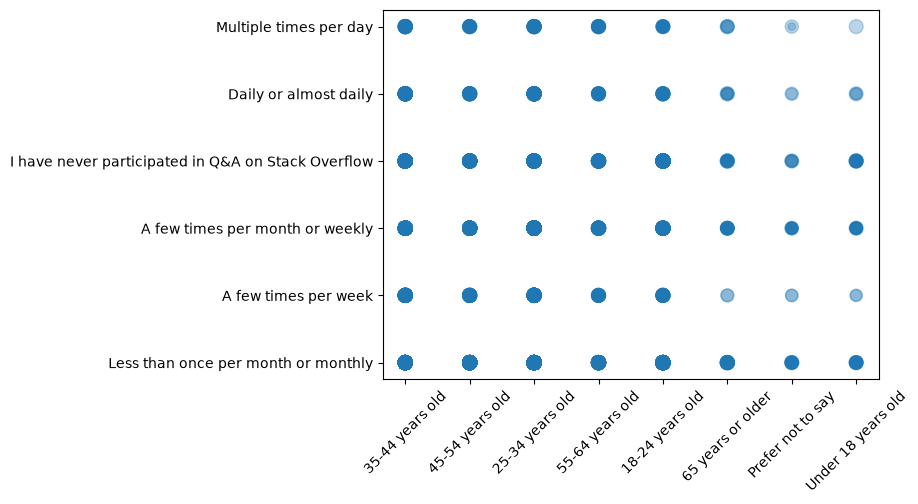

In [5]:
##Write your code here
d = df[["Age", "SOPartFreq", "JobSat"]].dropna() 
plt.scatter(d["Age"], d["SOPartFreq"], s=d["JobSat"] * 10, alpha=0.3) 
plt.xticks(rotation=45) 
plt.show()

The plot shows participation categories across several age groups, including respondents who participate frequently and those who have never taken part in Stack Overflow Q&A. Bubbles appear at many combinations, suggesting that participation habits vary within age groups rather than following one obvious age-based pattern.

#### 2. Bubble Plot for Compensation vs. Job Satisfaction


- Visualize the relationship between yearly compensation (`ConvertedCompYearly`) and job satisfaction (`JobSat`).
- Use the size of the bubbles to represent respondent's age.

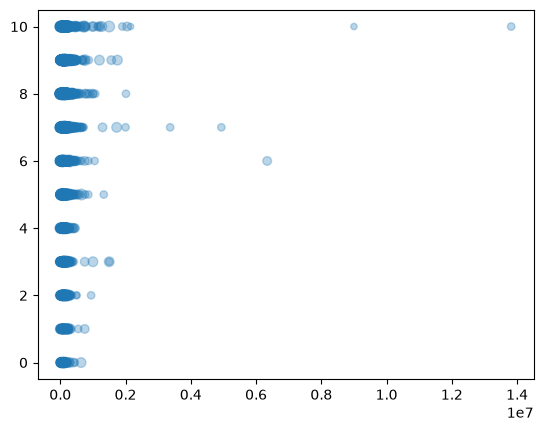

In [6]:
##Write your code here
age_map = {"18-24 years old": 21, "25-34 years old": 29, "35-44 years old": 39, "45-54 years old": 49, "55-64 years old": 59, "65 years or older": 70} 
plt.scatter(df["ConvertedCompYearly"], df["JobSat"], s=df["Age"].map(age_map), alpha=0.3) 
plt.show()

Most points are concentrated toward the lower end of the compensation axis, while a small number of extremely high reported salaries stretch the horizontal scale. Satisfaction values appear across a wide range at relatively low compensation levels. The saved plot does not show a clear, consistent increase in satisfaction as compensation rises.

### Task 2: Analyzing Relationships Using Bubble Plots


#### 1. Bubble Plot of Technology Preferences by Age

- Visualize the popularity of programming languages respondents have worked with (`LanguageHaveWorkedWith`) across age groups.
- Use bubble size to represent the frequency of each language.

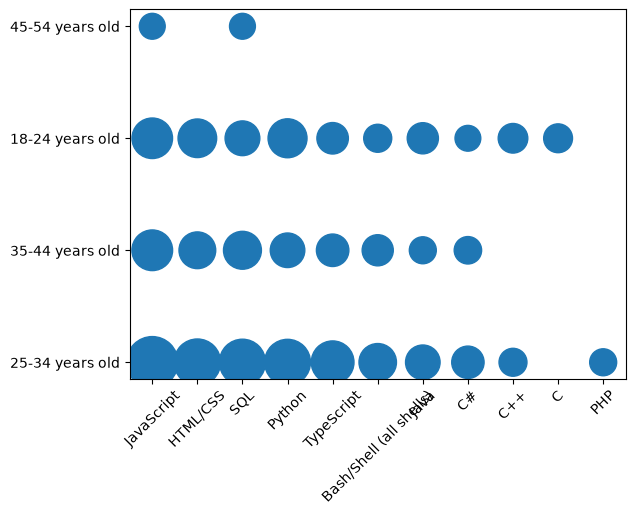

In [7]:
##Write your code here
d = df.assign(Lang=df["LanguageHaveWorkedWith"].str.split(";")).explode("Lang") 
c = d.groupby(["Lang", "Age"]).size().nlargest(30).reset_index(name="n") 
plt.scatter(c["Lang"], c["Age"], s=c["n"] / 10) 
plt.xticks(rotation=45)
plt.show()

The largest bubbles in the saved chart appear around widely reported languages and technologies such as JavaScript, HTML/CSS, SQL, and Python, particularly in the 25-34 and 18-24 age categories. The 35-44 group also appears repeatedly among the largest combinations.

#### 2. Bubble Plot for Preferred Databases vs. Job Satisfaction

- Explore the relationship between preferred databases (`DatabaseWantToWorkWith`) and job satisfaction.
- Use bubble size to indicate the number of respondents for each database.

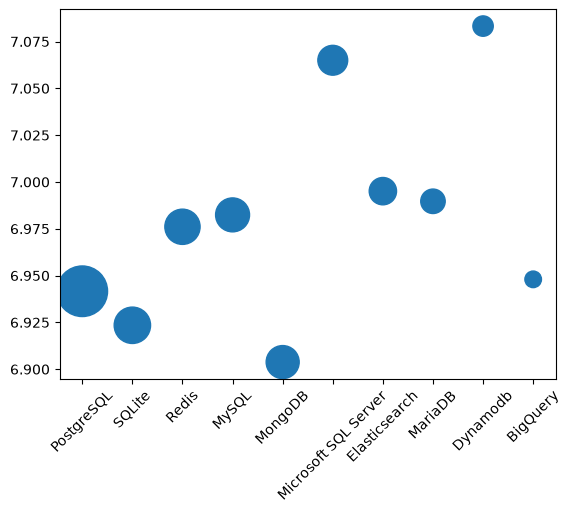

In [8]:
##Write your code here
d = df.assign(DB=df["DatabaseWantToWorkWith"].str.split(";")).explode("DB") 
s = d.groupby("DB")["JobSat"].agg(["count", "mean"]).nlargest(10, "count") 
plt.scatter(s.index, s["mean"], s=s["count"] / 10) 
plt.xticks(rotation=45)
plt.show()

Average satisfaction is tightly clustered, at approximately 6.9-7.1, across the ten displayed databases. DynamoDB appears near the higher end of the averages, while MongoDB is near the lower end. PostgreSQL has one of the largest bubbles, indicating many respondents with recorded satisfaction scores selected it.

### Task 3: Comparing Data Using Bubble Plots


#### 1. Bubble Plot for Compensation Across Developer Roles
- Visualize compensation (`ConvertedCompYearly`) across different developer roles (`DevType`).
- Use bubble size to represent job satisfaction.<br>
The chart shows median annual compensation for ten common developer-role categories after excluding salaries of $500,000 or more. Bubble size represents average job satisfaction for the role. It does not represent the number of developers in the role.

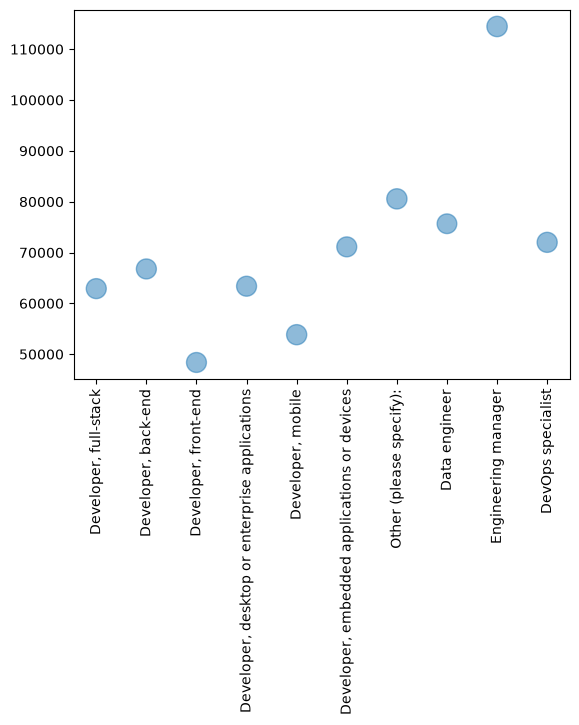

In [9]:
##Write your code here
d = df[df["ConvertedCompYearly"] < 500000] 
s = d.groupby("DevType").agg(comp=("ConvertedCompYearly", "median"), sat=("JobSat", "mean"), 
                             n=("JobSat", "size")).nlargest(10, "n") 
plt.scatter(s.index, s["comp"], s=s["sat"] * 30, alpha=0.5) 
plt.xticks(rotation=90)
plt.show()

Median compensation differs noticeably across the roles shown. Engineering manager is the highest plotted category, at roughly $113,000, while developer, front-end is among the lowest, at approximately $49,000. Several developer specializations cluster between about $60,000 and $80,000. Bubble sizes look relatively similar, suggesting that average satisfaction values do not differ dramatically across these roles in the saved chart.

#### 2. Bubble Plot for Collaboration Tools by Age
- Visualize the relationship between the collaboration tools used (`NEWCollabToolsHaveWorkedWith`) and age groups.
- Use bubble size to represent the frequency of tool usage.<br>
The chart counts mentions of collaboration tools within age categories. Larger bubbles represent more mentions, and only the 30 most frequent tool-age combinations appear. Because respondents may select multiple tools, the counts overlap across categories.

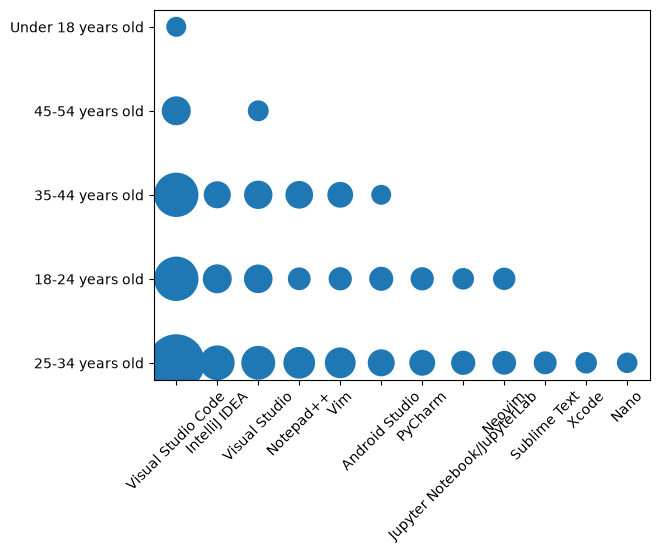

In [10]:
##Write your code here
d = df.assign(Tool=df["NEWCollabToolsHaveWorkedWith"].str.split(";")).explode("Tool") 
c = d.groupby(["Tool", "Age"]).size().nlargest(30).reset_index(name="n") 
plt.scatter(c["Tool"], c["Age"], s=c["n"] / 10) 
plt.xticks(rotation=45)
plt.show()

Visual Studio Code has particularly large bubbles in the 25-34, 18-24, and 35-44 age groups, indicating frequent mentions in those combinations. IntelliJ IDEA, Visual Studio, and Notepad++ also appear among the selected high-frequency combinations.

The 25-34 age category contains many of the displayed combinations. This may partly reflect its size in the survey rather than a stronger preference for every tool. The plot does not establish that a given tool is uniquely preferred by a particular age group.

### Task 4: Visualizing Technology Trends Using Bubble Plots


#### 1. Bubble Plot for Preferred Web Frameworks vs. Job Satisfaction
- Explore the relationship between preferred web frameworks (`WebframeWantToWorkWith`) and job satisfaction.
- Use bubble size to represent the number of respondents.<br>
The ten web frameworks with the most non-missing satisfaction responses are compared using their average job-satisfaction scores. Bubble size represents the number of respondents included in each framework's average.

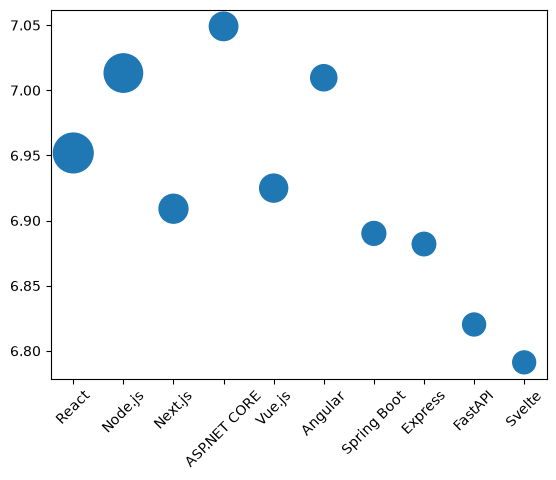

In [11]:
##Write your code here
d = df.assign(WF=df["WebframeWantToWorkWith"].str.split(";")).explode("WF") 
s = d.groupby("WF")["JobSat"].agg(["count", "mean"]).nlargest(10, "count") 
plt.scatter(s.index, s["mean"], s=s["count"] / 10) 
plt.xticks(rotation=45)
plt.show()

The mean satisfaction scores for the ten selected frameworks occupy a narrow range, approximately 6.8-7.05. ASP.NET Core is near the top of the chart, while Svelte and FastAPI are near the bottom. React has one of the largest bubbles, indicating a relatively large number of respondents with satisfaction data.

#### 2. Bubble Plot for Admired Technologies Across Countries
- Visualize the distribution of admired technologies (`LanguageAdmired`) across different countries (`Country`).
- Use bubble size to represent the frequency of admiration.<br>
This chart counts admired programming languages by country. The 30 largest country-language combinations are displayed, with bubble size indicating the number of mentions. The chart does not adjust for differences in the number of respondents from each country.

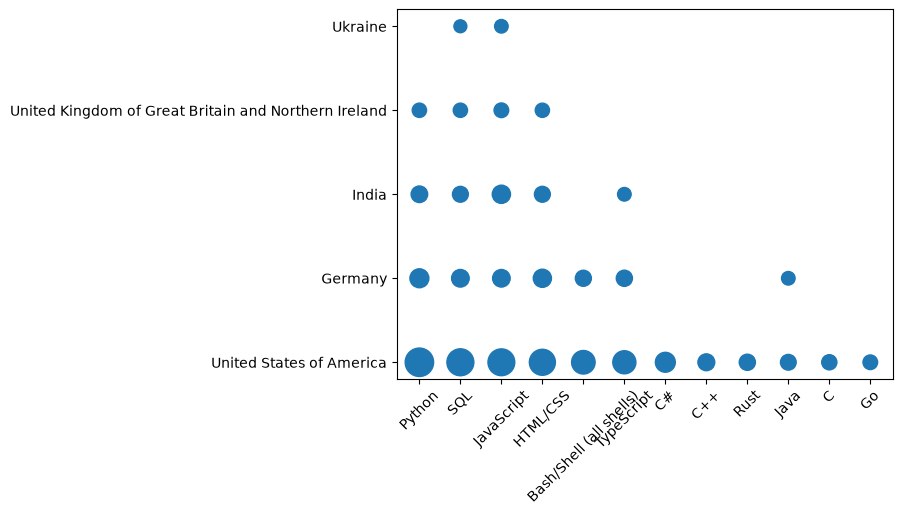

In [12]:
##Write your code here
d = df.assign(Lang=df["LanguageAdmired"].str.split(";")).explode("Lang") 
c = d.groupby(["Lang", "Country"]).size().nlargest(30).reset_index(name="n") 
plt.scatter(c["Lang"], c["Country"], s=c["n"] / 10) 
plt.xticks(rotation=45)
plt.show()

The United States appears across many of the displayed language combinations, with especially large bubbles for Python, SQL, JavaScript, and HTML/CSS. Germany, India, the United Kingdom, and Ukraine also appear among the top 30 combinations.

The United States' prominence may reflect a larger number of survey participants, rather than a higher proportion of developers admiring those languages.

### Key Findings
The eight charts show how developer survey responses vary across demographic groups, technology choices, compensation, and job satisfaction. Several patterns stand out:
- Compensation is highly uneven. A small number of exceptionally large values stretch the scale and obscure the central concentration of responses.
- Job-satisfaction averages are relatively close across the displayed database and web-framework groups. Small differences should not be interpreted as technology-driven effects.
- JavaScript, Python, HTML/CSS, and SQL appear frequently in the selected language comparisons. These are counts of survey mentions, not market-demand estimates.
- Median compensation varies across developer roles. Engineering manager is the highest plotted role in the filtered comparison.
- Raw bubble sizes reflect counts in several technology charts. Differences in survey-group sizes mean these counts should not be treated as preference rates.

### Limitations and Next Steps
The survey reflects its respondents rather than a complete census of developers. Many technology questions allow multiple selections, so groups overlap. Several plots show only the largest 10 or 30 categories, and raw counts are not normalized for age or country sample sizes. Some charts have substantial overplotting. The compensation analysis also needs careful validation of extreme values and currency comparability.

To strengthen this work, I would compare within-group percentages, add sample sizes and uncertainty intervals, validate compensation values, and use alternative plots when bubbles overlap heavily.

### Skills Demonstrated
- Data preparation: Filtering records, splitting multi-select responses, and handling missing values.
- Data analysis: Grouping, counting, calculating means and medians, and selecting high-frequency categories.
- Visualization: Building and interpreting bubble plots with Matplotlib.
- Analytical communication: Describing visible patterns while identifying limitations and avoiding unsupported causal claims.

### Summary


After completing this lab, you will be able to:
- Create and interpret bubble plots to analyze relationships and compositions within datasets.
- Use bubble plots to explore developer preferences, compensation trends, and satisfaction levels.
- Apply buBble plots to visualize complex relationships involving multiple dimensions effectively.

*Attribution: Original instructional content, source material, branding, and copyright belong to IBM Skills Network. Chart interpretations and portfolio documentation were added.*

### Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


<!--
## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2024-10-29|1.2|Madhusudhan Moole|Updated lab|
|2024-10-16|1.1|Madhusudhan Moole|Updated lab|
|2024-10-15|1.0|Raghul Ramesh|Created lab|
--!>


Copyright © IBM Corporation. All rights reserved.
